# VL53L7CX Ranging Log Analysis

This notebook loads `run1.csv` (produced by `tools/csv_logger.py`) and walks
through understanding the columns, cleaning the data, and analyzing a
**straight-line max-range characterization test** — where you move a matte
black notebook (or other target) directly away from the sensor while the
ranging loop streams continuously.

**Column reference** (one row = one zone, in one frame):

| Column | Meaning |
|---|---|
| `seq` | Frame sequence number, incremented once per ranging frame (not per zone). Multiple rows share the same `seq` — one per zone in that frame. |
| `timestamp_ms` | `HAL_GetTick()` value at frame build time — milliseconds since MCU boot, **not** wall-clock time. Use it to compute elapsed time / frame period, not absolute time of day. |
| `zone` | Flat zone index, `0..63` for 8x8 (`zone = row*grid_width + col`). |
| `row`, `col` | 2D position of the zone in the sensor's FOV grid. `row 0` = top of FOV, `col 0` = sensor's left (per the convention documented in `cloud.py`). |
| `distance_mm` | Measured distance to the closest (or strongest, depending on `TARGET_ORDER`) target in that zone's cone, in millimeters. This is the core ranging output. |
| `sigma_mm` | The sensor's own reported uncertainty (standard deviation) of `distance_mm`. Low sigma = confident measurement; sigma tends to grow as range increases and signal weakens. |
| `status` | Target status code. `5` = valid, `9` = valid but possibly a merged/blended target (e.g. an edge between two surfaces at different depths). Other codes generally indicate low-confidence or invalid returns — see ST's `vl53l7cx_api.h` for the full table. |
| `signal_kcps` | Return signal strength in kilo-counts-per-second per SPAD (`signal_per_spad`). This is your direct proxy for reflected IR strength — the number that actually degrades as your target moves further away or gets darker/less reflective. |
| `ambient_kcps` | Ambient (background) IR strength per SPAD, per zone. High ambient (e.g. sunlight) is what eventually swamps `signal_kcps` and is often the real range-limiter, not raw distance alone. |

**Why this matters for your straight-line test:** `distance_mm` alone only
tells you the sensor *thinks* it sees something — it does **not** tell you
whether that reading is trustworthy at long range. The real story is in how
`signal_kcps` decays and `sigma_mm`/`status` degrade as `distance_mm` grows.
The point where `status` stops being `5`/`9` and `sigma_mm` blows up is your
sensor's *practical* max range — not necessarily where `distance_mm` first
looks wrong.


## 1. Import Required Libraries


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Optional but nicer default styling; comment out if seaborn isn't installed
try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
except ImportError:
    pass

pd.set_option('display.max_columns', None)


## 2. Load Data

`run1.csv` is a plain CSV, not an `.xlsx` file (it opens fine in Excel, but
it's written by `csv.writer`, not `openpyxl`) — so we use `pd.read_csv()`
here rather than `pd.read_excel()`. If you save a cleaned/reprocessed copy
as an actual `.xlsx` later (see the export section at the bottom), that one
would use `read_excel()`.


In [3]:
CSV_PATH = "../run2.csv"  # adjust if your log lives elsewhere

df = pd.read_csv(CSV_PATH)
df.head()


,seq,timestamp_ms,zone,row,col,distance_mm,sigma_mm,status,signal_kcps,ambient_kcps
0,826,80687,0,0,0,546,7,5,23,1
1,826,80687,1,0,1,613,8,5,9,0
2,826,80687,2,0,2,629,10,5,4,1
3,826,80687,3,0,3,672,15,5,6,0
4,826,80687,4,0,4,271,2,5,110,1


## 3. Inspect and Describe Columns

Column-by-column reference (see also the intro cell at the top):

- **seq** (int) — frame counter, repeats across all zones of the same frame.
- **timestamp_ms** (int) — MCU tick count in ms at frame capture; monotonic but boot-relative.
- **zone** (int, 0-63) — flat zone index.
- **row, col** (int) — 2D grid position; row 0 = top of FOV, col 0 = sensor's left.
- **distance_mm** (int) — measured range to target in this zone's cone.
- **sigma_mm** (int) — sensor-reported measurement uncertainty.
- **status** (int) — target validity code (5 = valid, 9 = valid/merged; others = suspect).
- **signal_kcps** (int) — reflected IR signal strength per SPAD (kcps).
- **ambient_kcps** (int) — background IR strength per SPAD (kcps).

Run the cell below to confirm dtypes and check nothing parsed as an
unexpected type (e.g. distances read as strings).


In [4]:
print(df.shape)
print(df.dtypes)
print("\nFrames captured:", df['seq'].nunique())
print("Zones per frame (should be 64 for 8x8):", df.groupby('seq').size().mode()[0])


(44288, 10)
seq             int64
timestamp_ms    int64
zone            int64
row             int64
col             int64
distance_mm     int64
sigma_mm        int64
status          int64
signal_kcps     int64
ambient_kcps    int64
dtype: object

Frames captured: 692
Zones per frame (should be 64 for 8x8): 64


## 4. Summary Statistics

`describe()` gives a quick feel for the overall run: is `distance_mm`
spanning the range you expect, is `signal_kcps` mostly reasonable or mostly
near zero (bad aim/no target), etc. Split by `status` too, since invalid
rows will otherwise skew the numbers.


In [5]:
display(df[['distance_mm', 'sigma_mm', 'signal_kcps', 'ambient_kcps']].describe())

print("\nStatus code counts:")
print(df['status'].value_counts())


,distance_mm,sigma_mm,signal_kcps,ambient_kcps
count,44288.00000,44288.000000,44288.000000,44288.000000
mean,612.72873,18.233607,174.012170,1.086389
std,897.28837,20.630631,350.648584,1.073784
min,0.00000,0.000000,1.000000,0.000000
25%,108.00000,2.000000,3.000000,0.000000
50%,219.00000,15.000000,8.000000,1.000000
75%,730.00000,26.000000,206.000000,2.000000
max,4206.00000,346.000000,1667.000000,5.000000



Status code counts:
status
255    22427
5      20778
10       808
4        125
2         77
9         52
3         21
Name: count, dtype: int64


## 5. Data Cleaning and Type Conversion

- Check for missing/duplicate rows (shouldn't happen given the firmware
  writes fixed-size frames, but corrupted/dropped serial frames could
  cause gaps in `seq`).
- Convert `timestamp_ms` into a proper elapsed-seconds column, and add a
  human-readable `elapsed_s` so plots have a real x-axis instead of raw
  MCU ticks.
- Add an `is_valid` flag from `status` so later cells can filter easily.


In [6]:
print("Missing values per column:\n", df.isna().sum())
print("\nDuplicate (seq, zone) pairs:", df.duplicated(subset=['seq', 'zone']).sum())

# Detect gaps in sequence numbers -> dropped/corrupt serial frames
seqs = sorted(df['seq'].unique())
gaps = [ (a, b) for a, b in zip(seqs, seqs[1:]) if b - a > 1 ]
print(f"\nSequence gaps detected: {len(gaps)}")
if gaps[:5]:
    print("First few gaps (seq_before, seq_after):", gaps[:5])

# Elapsed time relative to the first frame, in seconds
df['elapsed_s'] = (df['timestamp_ms'] - df['timestamp_ms'].min()) / 1000.0

# Convenience validity flag: 5 = valid, 9 = valid but possibly merged targets
df['is_valid'] = df['status'].isin([5, 9])

df.head()


Missing values per column:
 seq             0
timestamp_ms    0
zone            0
row             0
col             0
distance_mm     0
sigma_mm        0
status          0
signal_kcps     0
ambient_kcps    0
dtype: int64

Duplicate (seq, zone) pairs: 0

Sequence gaps detected: 0


,seq,timestamp_ms,zone,row,col,distance_mm,sigma_mm,status,signal_kcps,ambient_kcps,elapsed_s,is_valid
0,826,80687,0,0,0,546,7,5,23,1,0.0,True
1,826,80687,1,0,1,613,8,5,9,0,0.0,True
2,826,80687,2,0,2,629,10,5,4,1,0.0,True
3,826,80687,3,0,3,672,15,5,6,0,0.0,True
4,826,80687,4,0,4,271,2,5,110,1,0.0,True


## 6. Visualize Raw Ranging Data

Before doing any characterization math, just look at the raw center-zone
distance trace over time. For an 8x8 grid, zone 27 or 36 sits near dead
center (row/col 3 or 4). This tells you at a glance whether the sensor
tracked your notebook cleanly as you walked it away, or lost/jumped lock.


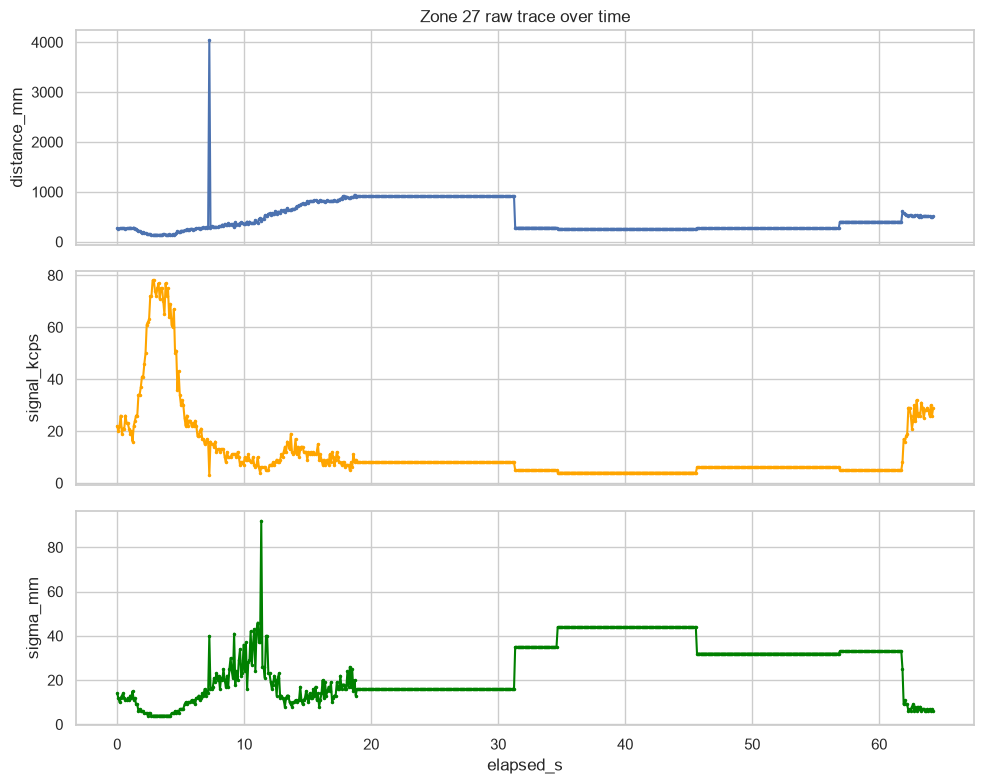

In [7]:
CENTER_ZONE = 27  # row 3, col 3 on an 8x8 grid; adjust if you used 4x4

center = df[df['zone'] == CENTER_ZONE].sort_values('elapsed_s')

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].plot(center['elapsed_s'], center['distance_mm'], '.-', ms=3)
axes[0].set_ylabel('distance_mm')
axes[0].set_title(f'Zone {CENTER_ZONE} raw trace over time')

axes[1].plot(center['elapsed_s'], center['signal_kcps'], '.-', color='orange', ms=3)
axes[1].set_ylabel('signal_kcps')

axes[2].plot(center['elapsed_s'], center['sigma_mm'], '.-', color='green', ms=3)
axes[2].set_ylabel('sigma_mm')
axes[2].set_xlabel('elapsed_s')

plt.tight_layout()
plt.show()


## 7. Straight-Line Characterization Analysis

**The catch:** `run1.csv` only has the sensor's *own* `distance_mm` — it has
no independent "ground truth" distance, because the firmware doesn't know
where you actually are. Just plotting `distance_mm` vs `elapsed_s` tells you
what the sensor *reported*, not whether it was *correct*.

**Two ways to get a ground truth for a straight-line test:**

1. **Simplest — a tape measure + manual checkpoints.** While logging
   continuously, pause briefly at known distances (e.g. every 0.5 m) and
   note the `elapsed_s` (or just eyeball the timestamp) at each pause. Build
   a small lookup table by hand and merge it in below. This is what the
   cell below assumes (edit `checkpoints` to match your actual run).
2. **Best — walk at a known, constant speed.** If you move the notebook
   away at a roughly constant pace (e.g. using a wheeled cart, or timing
   yourself with a metronome/steady walk), you can approximate
   `reference_mm = start_mm + speed_mm_s * elapsed_s` for the whole run
   without needing checkpoints, then just eyeball/trim the section where
   your motion was actually steady.

Either way, the goal is a `reference_mm` column to compare against.


In [8]:
# --- Option A: checkpoint method -------------------------------------------
# Fill this in with (elapsed_s, reference_mm) pairs you noted during the run,
# e.g. "at t=4.0s the notebook was at 1000mm, at t=9.5s it was at 2000mm..."
checkpoints = [
    (0.0, 300),
    # (4.0, 1000),
    # (9.5, 2000),
    # (15.0, 3000),
]

if len(checkpoints) >= 2:
    cp_t, cp_d = zip(*checkpoints)
    # Linear interpolation between your manually-noted checkpoints
    center = center.copy()
    center['reference_mm'] = np.interp(center['elapsed_s'], cp_t, cp_d)
else:
    print("Add at least 2 checkpoints above (or use Option B) before continuing.")
    center = center.copy()
    center['reference_mm'] = np.nan

# --- Option B: constant-speed method (uncomment and tune instead) ---------
# START_MM = 300        # distance at t=0
# SPEED_MM_S = 200      # your approx walking speed away from the sensor
# center['reference_mm'] = START_MM + SPEED_MM_S * center['elapsed_s']

center[['elapsed_s', 'distance_mm', 'reference_mm']].head()


Add at least 2 checkpoints above (or use Option B) before continuing.


,elapsed_s,distance_mm,reference_mm
27,0.000,270,NaN
91,0.093,266,NaN
155,0.186,269,NaN
219,0.279,276,NaN
283,0.372,272,NaN


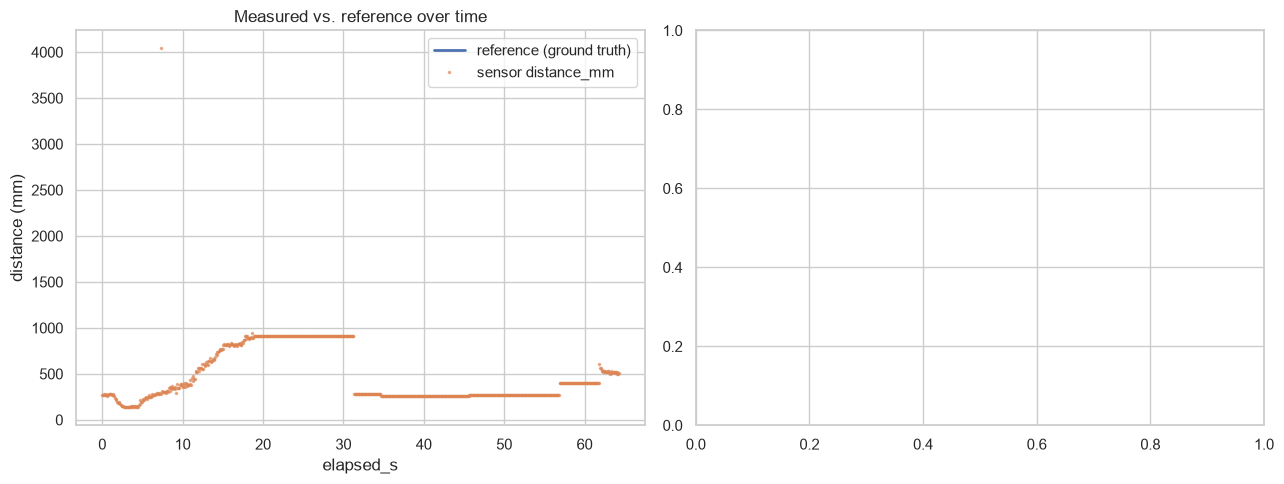

In [8]:
# Plot measured vs. reference distance over time, plus a scatter of
# measured vs. reference with a fitted line to check linearity.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(center['elapsed_s'], center['reference_mm'], label='reference (ground truth)', lw=2)
axes[0].plot(center['elapsed_s'], center['distance_mm'], '.', ms=3, alpha=0.6, label='sensor distance_mm')
axes[0].set_xlabel('elapsed_s')
axes[0].set_ylabel('distance (mm)')
axes[0].set_title('Measured vs. reference over time')
axes[0].legend()

valid = center.dropna(subset=['reference_mm'])
if len(valid) > 1:
    coeffs = np.polyfit(valid['reference_mm'], valid['distance_mm'], 1)
    fit_x = np.linspace(valid['reference_mm'].min(), valid['reference_mm'].max(), 100)
    fit_y = np.polyval(coeffs, fit_x)

    axes[1].scatter(valid['reference_mm'], valid['distance_mm'], s=8, alpha=0.5, label='samples')
    axes[1].plot(fit_x, fit_x, 'k--', label='ideal (y=x)')
    axes[1].plot(fit_x, fit_y, 'r-', label=f'fit: y={coeffs[0]:.3f}x+{coeffs[1]:.1f}')
    axes[1].set_xlabel('reference_mm')
    axes[1].set_ylabel('distance_mm (measured)')
    axes[1].set_title('Linearity check')
    axes[1].legend()

plt.tight_layout()
plt.show()


### The most important plot: signal strength & confidence vs. distance

This is what actually answers "how far can it realistically see" — not the
distance trace alone. Watch for the distance at which `signal_kcps` drops
toward the noise floor and `status` stops being valid (5/9): that's your
practical max range for a matte black target, which will be **shorter**
than the datasheet's max range (dark, low-reflectivity targets return much
less signal than the white/gray reference target ST rates the sensor with).


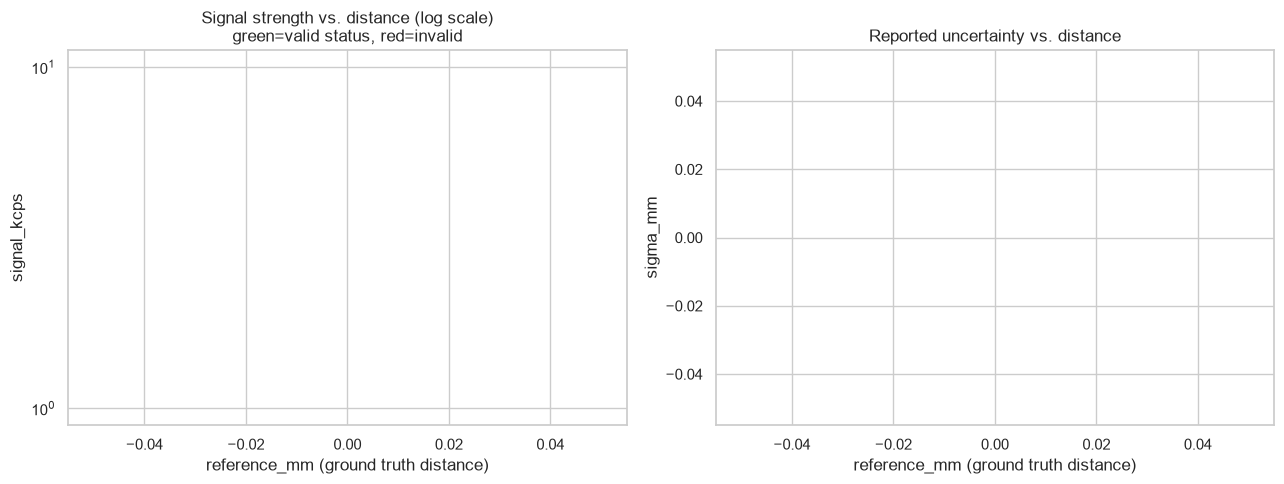

Furthest reference distance with a VALID status: nan mm


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = valid['is_valid'].map({True: 'tab:green', False: 'tab:red'})

axes[0].scatter(valid['reference_mm'], valid['signal_kcps'], c=colors, s=10, alpha=0.7)
axes[0].set_xlabel('reference_mm (ground truth distance)')
axes[0].set_ylabel('signal_kcps')
axes[0].set_yscale('log')
axes[0].set_title('Signal strength vs. distance (log scale)\ngreen=valid status, red=invalid')

axes[1].scatter(valid['reference_mm'], valid['sigma_mm'], c=colors, s=10, alpha=0.7)
axes[1].set_xlabel('reference_mm (ground truth distance)')
axes[1].set_ylabel('sigma_mm')
axes[1].set_title('Reported uncertainty vs. distance')

plt.tight_layout()
plt.show()

# Quick numeric summary: last reference distance where status was still valid
last_valid = valid[valid['is_valid']]['reference_mm'].max()
first_invalid = valid[~valid['is_valid']]['reference_mm'].min() if (~valid['is_valid']).any() else None
print(f"Furthest reference distance with a VALID status: {last_valid:.0f} mm")
if first_invalid is not None:
    print(f"Nearest reference distance with an INVALID status: {first_invalid:.0f} mm")


## 8. Error and Deviation Metrics

Compute RMSE / MAE between measured `distance_mm` and your `reference_mm`
ground truth, plus residuals. Also worth checking whether error grows with
distance (expected — sigma and signal both degrade with range) by binning
residuals into distance buckets.


RMSE:  nan mm
MAE:   nan mm
Bias (mean error): +nan mm


,mean,std,count
dist_bucket,,,


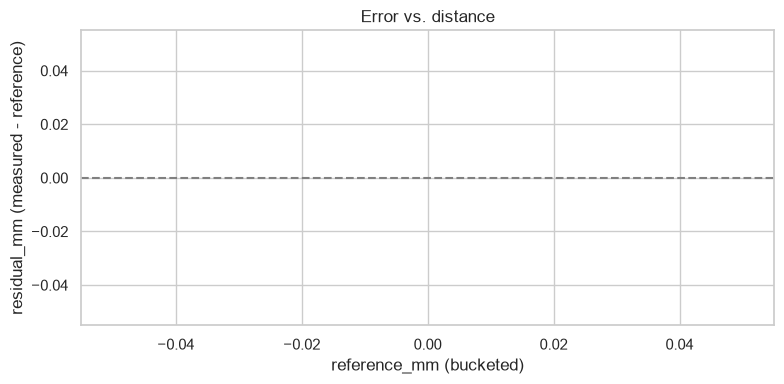

: 

In [ ]:
valid = valid.copy()
valid['residual_mm'] = valid['distance_mm'] - valid['reference_mm']

rmse = np.sqrt((valid['residual_mm'] ** 2).mean())
mae = valid['residual_mm'].abs().mean()
bias = valid['residual_mm'].mean()

print(f"RMSE:  {rmse:.1f} mm")
print(f"MAE:   {mae:.1f} mm")
print(f"Bias (mean error): {bias:+.1f} mm")

# Error vs. distance, bucketed every 250mm -- shows whether accuracy
# degrades with range, which it typically will.
valid['dist_bucket'] = (valid['reference_mm'] // 250 * 250).astype(int)
bucketed = valid.groupby('dist_bucket')['residual_mm'].agg(['mean', 'std', 'count'])
display(bucketed)

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(bucketed.index, bucketed['mean'], yerr=bucketed['std'], fmt='o-', capsize=3)
ax.axhline(0, color='gray', ls='--')
ax.set_xlabel('reference_mm (bucketed)')
ax.set_ylabel('residual_mm (measured - reference)')
ax.set_title('Error vs. distance')
plt.tight_layout()
plt.show()


## 9. Export Processed Results

Save the cleaned/annotated DataFrame (with `elapsed_s`, `is_valid`,
`reference_mm`, `residual_mm`) plus the summary metrics, so you have a
record of this specific test run without needing to re-run the analysis
from scratch each time.


In [ ]:
OUT_CSV = "../run1_processed.csv"
OUT_XLSX = "../run1_processed.xlsx"

valid.to_csv(OUT_CSV, index=False)

with pd.ExcelWriter(OUT_XLSX) as writer:
    valid.to_excel(writer, sheet_name='processed_data', index=False)
    bucketed.to_excel(writer, sheet_name='error_by_distance')
    pd.DataFrame({
        'metric': ['RMSE_mm', 'MAE_mm', 'bias_mm', 'max_valid_reference_mm'],
        'value': [rmse, mae, bias, last_valid],
    }).to_excel(writer, sheet_name='summary', index=False)

print(f"Saved: {OUT_CSV}")
print(f"Saved: {OUT_XLSX} (requires openpyxl: pip install openpyxl)")
